# Лабораторная работа № 14. Разработка нейрона на PyTorch
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение возможностей библиотеки PyTorch.

**Задачи:** разработать нейрон на PyTorch; сравнить функции потерь; исследовать обучение на простом и сложном наборах без добавления скрытых слоёв.

**Данные:** таблица «Яблоки и груши» из примера; трёхклассовая спираль «игрушка дьявола» из методички.

Работа выполнена по методичке *Practicum_AI_Methods.pdf*, с. 124–131. В цели исправлены только опечатки.

## 1. Локальный запуск и краткая теория
Используем окружение `rcaeval-ai`, VS Code и Jupyter. Выбираем ядро этого окружения и выполняем **Run All**. Для работ № 14–15 добавлен PyTorch с расчётами на CPU; видеокарта не нужна. Из корня проекта окружение обновляется командой:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```
Ноутбук выполняется самостоятельно. Сохранённые данные читаются локально; другие ноутбуки запускать не нужно. Результаты и рисунки сохраняются в `reports/labXX/`, где XX — номер работы.

Подключаем библиотеки для таблиц, файлов и рисунков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем методы обучения и проверки.

In [2]:
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, log_loss

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab14'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'torch']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
torch            2.14.1
Name: Версия, dtype: object

140

Определяем сохранение и показ рисунка.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Один нейрон вычисляет z = x₁w₁ + x₂w₂ + b. Sigmoid превращает z в вероятность класса 1. При пороге 0,5 ответ равен 1 тогда, когда z ≥ 0. Граница получается прямой. Шаг обучения определяет величину изменения весов, эпоха — один проход по обучающим данным.

В листингах методички используются устаревшие `Variable`, `.data` и `size_average`. Здесь достаточно Tensor, `torch.no_grad()` и `reduction`; смысл вычислений сохранён. Все расчёты выполняются на CPU.

Определяем области решения на рисунке.

In [6]:
def draw_boundary(ax, predict, X, y, title, names=None):
    low, high = X.min(axis=0) - 0.25, X.max(axis=0) + 0.25
    xx, yy = np.meshgrid(np.linspace(low[0], high[0], 180), np.linspace(low[1], high[1], 180))
    grid = np.c_[xx.ravel(), yy.ravel()]
    classes = np.unique(y)
    levels = np.arange(len(classes) + 1) - 0.5
    ax.contourf(xx, yy, predict(grid).reshape(xx.shape), levels=levels, cmap='coolwarm', alpha=0.22)
    for label in classes:
        rows = y == label
        name = str(label) if names is None else names[int(label)]
        ax.scatter(X[rows, 0], X[rows, 1], c=np.full(rows.sum(), label), cmap='coolwarm',
                   vmin=0, vmax=max(1, len(classes)-1), s=15, edgecolors='k', linewidths=0.2, label=name)
    ax.set(title=title, xlabel='Признак 1', ylabel='Признак 2', xlim=(low[0],high[0]), ylim=(low[1],high[1]))
    ax.legend(title='Настоящий класс', fontsize=8)

Определяем обучение сети: прямой проход, потери, градиенты и шаг.

In [7]:
def train_network(model, X, y, optimizer, loss_fn, epochs):
    x_tensor = torch.as_tensor(X, dtype=torch.float32)
    y_tensor = torch.as_tensor(y, dtype=torch.long)
    history = []
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(x_tensor), y_tensor)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return history

Определяем получение классов без вычисления градиентов.

In [8]:
def predict_network(model, X):
    model.eval()
    with torch.no_grad():
        output = model(torch.as_tensor(X, dtype=torch.float32))
        if output.shape[1] == 1:
            return (output[:, 0] >= 0).numpy().astype(int)
        return output.argmax(dim=1).numpy()

Задаём три функции потерь для одного бинарного нейрона.

In [9]:
def binary_loss(logits, target, kind):
    if kind == 'MSE':
        return nn.MSELoss(reduction='sum')(logits.sigmoid()[:, 0], target.float())
    scores = torch.cat([torch.zeros_like(logits), logits], dim=1)
    if kind == 'NLL':
        return nn.NLLLoss()(F.log_softmax(scores, dim=1), target)
    return nn.CrossEntropyLoss()(scores, target)

NLLLoss принимает **логарифмы вероятностей**, CrossEntropyLoss — **оценки до softmax**. В PyTorch функция называется `CrossEntropyLoss`, а не `CrossEntropy`.

У бинарного нейрона один обучаемый выход z. Для NLL и CrossEntropy собираем две оценки [0, z]: softmax даёт те же вероятности [1−sigmoid(z), sigmoid(z)]. Нулевая оценка не имеет весов, не добавляет нейрон и не меняет архитектуру. Поэтому можно сравнить требуемые функции потерь, сохранив один нейрон. NLL и CrossEntropy при такой записи математически эквивалентны. MSE в исходном примере суммируется, а остальные потери усредняются; их численные значения напрямую не сравниваем.

Определяем создание и обучение одного нейрона с заданными настройками.

In [10]:
def fit_neuron(X, y, config):
    torch.manual_seed(SEED)
    model = nn.Sequential(nn.Linear(2, 1))
    optimizer_class = {'SGD': torch.optim.SGD, 'Adam': torch.optim.Adam}[config['optimizer']]
    optimizer = optimizer_class(model.parameters(), lr=config['lr'])
    loss_fn = lambda logits, target: binary_loss(logits, target, config['loss'])
    history = train_network(model, X, y, optimizer, loss_fn, config['epochs'])
    return model, history

def binary_probabilities(model, X):
    with torch.no_grad():
        return model(torch.as_tensor(X, dtype=torch.float32)).sigmoid()[:, 0].numpy()

## 2. Учебная задача: «Яблоки и груши»
### 2.1. Исходная таблица
Используем файл учебного курса DLSchool с тем же названием, что в методичке. Он содержит две числовые характеристики и ответ `target` 0/1. Это готовый учебный набор; реальные измерения фруктов из его названия не следуют.

Порядок признаков берём из CSV: `yellowness` — желтизна, `symmetry` — симметричность. В подписи рисунка методички они переставлены. Соответствие номеров классов конкретным фруктам в CSV не описано, поэтому используем обозначения 0 и 1.

Получаем файл примера только при отсутствии локальной копии.

In [11]:
apple_path = ROOT / 'data/raw/neural_examples/apples_pears.csv'
apple_path.parent.mkdir(parents=True, exist_ok=True)
apple_url = 'https://raw.githubusercontent.com/DLSchool/dlschool_old/6a0084864d3dd72e19b9bc818fcf4fced6d275cd/materials/homeworks/hw04/data/apples_pears.csv'
if not apple_path.exists():
    apple_path.write_bytes(urlopen(apple_url, timeout=60).read())

Загружаем таблицу.

In [12]:
apples = pd.read_csv(apple_path)

Показываем строки, размер и число примеров каждого класса.

In [13]:
display(apples.head())
print('Размер:', apples.shape)
display(apples.target.value_counts().sort_index().rename('Объектов'))
Xa = apples[['yellowness', 'symmetry']].to_numpy(dtype=np.float32)
ya = apples.target.to_numpy(dtype=np.int64)

,yellowness,symmetry,target
0,0.779427,0.257305,1.0
1,0.777005,0.015915,1.0
2,0.977092,0.304210,1.0
3,0.043032,0.140899,0.0
4,0.760433,0.193123,1.0


Размер: (1000, 3)


target
0.0    412
1.0    588
Name: Объектов, dtype: int64

Показываем исходные характеристики фруктов.

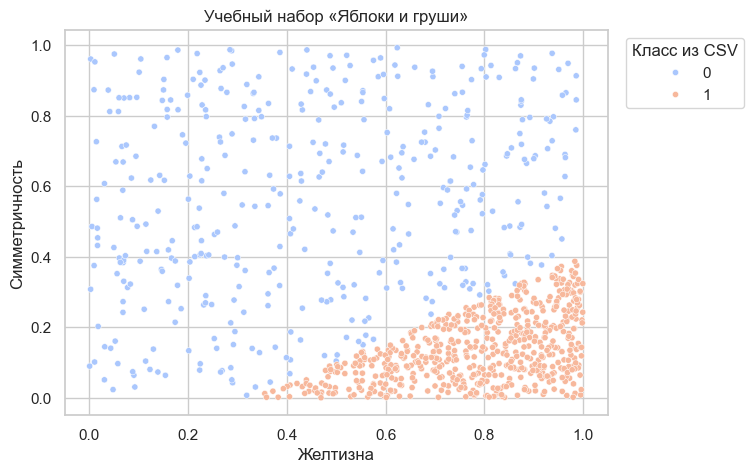

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=Xa[:, 0], y=Xa[:, 1], hue=ya.astype(str), hue_order=['0', '1'], palette='coolwarm', s=20, ax=ax)
ax.set(title='Учебный набор «Яблоки и груши»', xlabel='Желтизна', ylabel='Симметричность')
ax.legend(title='Класс из CSV', loc='upper left', bbox_to_anchor=(1.02, 1))
save_show(fig, '01_apples_data.png')

Каждая точка — строка файла, цвет — её класс. Признаки находятся в диапазоне примерно 0–1. Видно, можно ли провести между цветами почти прямую границу: именно такие разделения доступны одному нейрону.

Отделяем обучение, подбор и итоговую проверку; обучаем масштаб только на обучении.

In [15]:
a_develop, a_test = train_test_split(np.arange(len(ya)), test_size=0.2, stratify=ya, random_state=SEED)
a_train, a_valid = train_test_split(a_develop, test_size=0.25, stratify=ya[a_develop], random_state=SEED)
a_scaler = StandardScaler().fit(Xa[a_train])
a_train_X, a_valid_X, a_test_X = [a_scaler.transform(Xa[rows]).astype(np.float32)
                                 for rows in [a_train, a_valid, a_test]]
print('Обучение:', len(a_train), '| Подбор:', len(a_valid), '| Итоговая проверка:', len(a_test))

Обучение: 600 | Подбор: 200 | Итоговая проверка: 200


Создаём необученный нейрон и показываем его ответ.

In [16]:
torch.manual_seed(SEED)
untrained = nn.Sequential(nn.Linear(2, 1))
print(untrained)
print('Число обучаемых параметров:', sum(p.numel() for p in untrained.parameters()))
print('Вероятность класса 1 для [1, 1]:', binary_probabilities(untrained, a_scaler.transform([[1, 1]]))[0])

Sequential(
  (0): Linear(in_features=2, out_features=1, bias=True)
)
Число обучаемых параметров: 3
Вероятность класса 1 для [1, 1]: 0.6141688


У нейрона два веса и одно смещение — всего три обучаемых числа. До обучения его вероятность зависит от начальных случайных весов и пока не является полезным распознаванием фруктов.

### 2.2. Улучшаем шаг, число эпох и функцию потерь
Первый вариант повторяет исходные MSE с суммой, SGD, шаг 0,001 и 500 эпох. Затем меняем настройки, не меняя один нейрон. Выбор делаем по отдельной части для подбора: сначала accuracy, при равенстве — меньшая LogLoss, рассчитанная одинаково для всех моделей.

Задаём исходный вариант и варианты улучшения.

In [17]:
apple_configs = [
    {'name': 'Исходный MSE', 'loss': 'MSE', 'optimizer': 'SGD', 'lr': 0.001, 'epochs': 500},
    {'name': 'MSE дольше', 'loss': 'MSE', 'optimizer': 'SGD', 'lr': 0.001, 'epochs': 3000},
    {'name': 'NLL + SGD', 'loss': 'NLL', 'optimizer': 'SGD', 'lr': 0.1, 'epochs': 3000},
    {'name': 'CE + SGD', 'loss': 'CE', 'optimizer': 'SGD', 'lr': 0.1, 'epochs': 3000},
    {'name': 'CE + Adam', 'loss': 'CE', 'optimizer': 'Adam', 'lr': 0.03, 'epochs': 3000}
]

Обучаем варианты одного нейрона и сравниваем на части для подбора.

In [18]:
apple_models, apple_histories, apple_rows = {}, {}, []
for config in apple_configs:
    name = config['name']
    model, history = fit_neuron(a_train_X, ya[a_train], config)
    apple_models[name], apple_histories[name] = model, history
    probability = binary_probabilities(model, a_valid_X)
    apple_rows.append({**config, 'valid_accuracy': accuracy_score(ya[a_valid], probability >= 0.5),
                       'valid_logloss': log_loss(ya[a_valid], probability)})
apple_table = pd.DataFrame(apple_rows)
display(apple_table)
apple_best = apple_table.sort_values(['valid_accuracy', 'valid_logloss'], ascending=[False, True]).iloc[0]['name']
print('Выбрано по части подбора:', apple_best)

,name,loss,optimizer,lr,epochs,valid_accuracy,valid_logloss
0,Исходный MSE,MSE,SGD,0.001,500,0.985,0.100915
1,MSE дольше,MSE,SGD,0.001,3000,0.995,0.056408
2,NLL + SGD,NLL,SGD,0.100,3000,0.990,0.057856
3,CE + SGD,CE,SGD,0.100,3000,0.990,0.057856
4,CE + Adam,CE,Adam,0.030,3000,1.000,0.021092


Выбрано по части подбора: CE + Adam


Показываем исходную и выбранную границы на части для подбора.

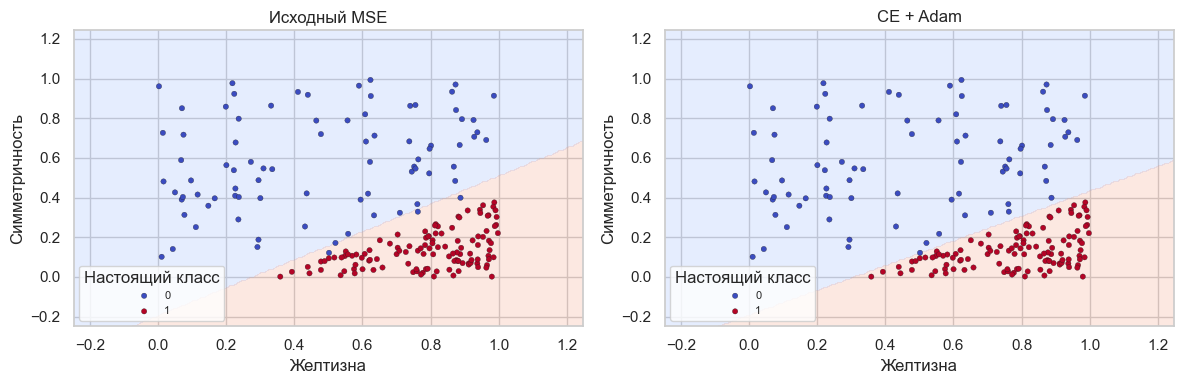

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ['Исходный MSE', apple_best]):
    predict = lambda raw, name=name: predict_network(apple_models[name], a_scaler.transform(raw))
    draw_boundary(ax, predict, Xa[a_valid], ya[a_valid], name)
    ax.set(xlabel='Желтизна', ylabel='Симметричность')
fig.tight_layout()
save_show(fig, '02_apples_boundaries.png')

Слева исходная настройка, справа вариант, выбранный по отдельным точкам. Оба разделяют плоскость прямой: мы меняли обучение, а не возможности одного нейрона. Цвета точек показывают ответы CSV; фон — ответы сети. Итоговая тестовая часть в выборе не участвовала.

Показываем потери по эпохам отдельно для MSE и логарифмических потерь.

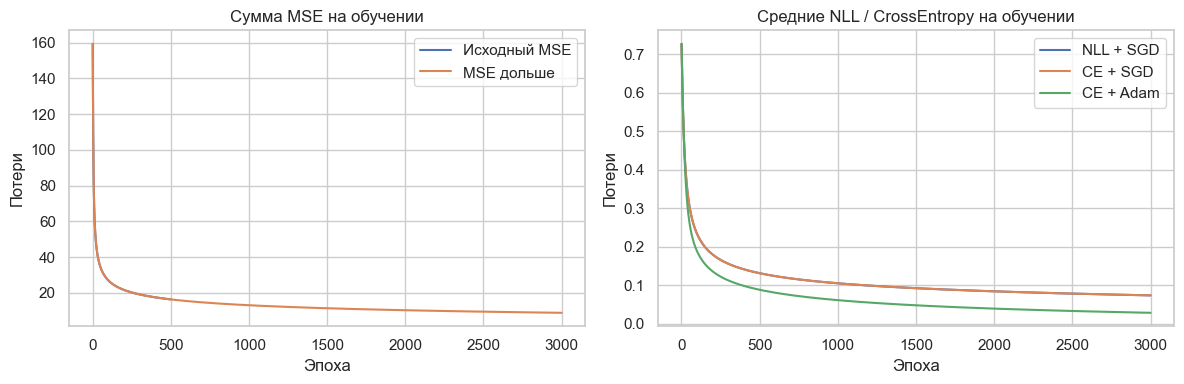

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for config in apple_configs:
    name = config['name']
    ax = axes[0] if config['loss'] == 'MSE' else axes[1]
    ax.plot(np.arange(1, len(apple_histories[name]) + 1), apple_histories[name], label=name)
for ax, title in zip(axes, ['Сумма MSE на обучении', 'Средние NLL / CrossEntropy на обучении']):
    ax.set(title=title, xlabel='Эпоха', ylabel='Потери')
    ax.legend()
fig.tight_layout()
save_show(fig, '03_apples_loss.png')

Потери должны уменьшаться по мере подбора весов. Шкалы двух панелей имеют разный смысл, поэтому нельзя объявить MSE лучше CrossEntropy по высоте линии. NLL и CE при одинаковом старте и шаге дают практически одинаковые линии, потому что здесь считают одну и ту же величину.

Один раз проверяем исходный и выбранный варианты на итоговых данных.

In [21]:
apple_test_rows = []
for name in dict.fromkeys(['Исходный MSE', apple_best]):
    probability = binary_probabilities(apple_models[name], a_test_X)
    apple_test_rows.append({'name': name, 'test_accuracy': accuracy_score(ya[a_test], probability >= 0.5),
                            'test_logloss': log_loss(ya[a_test], probability)})
apple_test_table = pd.DataFrame(apple_test_rows)
display(apple_test_table)

,name,test_accuracy,test_logloss
0,Исходный MSE,0.975,0.118163
1,CE + Adam,0.980,0.038741


Accuracy близкая к 1 означает, что нейрон почти всегда правильно различает эти две группы на новых строках того же учебного набора. Настройки после просмотра теста не меняем. Даже точность 100% на конечной выборке не гарантирует отсутствие ошибок на любых будущих фруктах.

## 3. Индивидуальное задание: «игрушка дьявола»
### 3.1. Три спирали из методички
В наборе 300 точек, по 100 на каждый из трёх классов. Используем формулу с с. 137: радиус 0–1, угол от 4j до 4(j+1) и шум 0,2. Seed фиксирован.

Обычный один нейрон с sigmoid выдаёт вероятность **двух**, а не трёх классов. Поэтому выполняем два явно разделённых опыта:

1. Строго один нейрон 2→1: все исходные точки, задача «класс 0 против классов 1 и 2». Ничего не удаляем, но отмечаем изменение постановки.
2. Исходные три класса: один линейный слой 2→3 без скрытых слоёв, по выходу на класс. Это три выходных нейрона, а не один. Он соответствует трём областям на рисунке с. 130.

Внутри **каждого** опыта архитектура, признаки, точки и разделение неизменны; улучшаем только обучение. Не добавляем скрытые слои или нелинейные входные признаки, чтобы не обойти ограничение задания.

Определяем создание трёх спиралей.

In [22]:
def make_spiral(seed=SEED):
    rng = np.random.RandomState(seed)
    N, D, K = 100, 2, 3
    X = np.zeros((N * K, D), dtype=np.float32)
    y = np.zeros(N * K, dtype=np.int64)
    for j in range(K):
        rows = range(N * j, N * (j + 1))
        r = np.linspace(0, 1, N)
        angle = np.linspace(j * 4, (j + 1) * 4, N) + rng.randn(N) * 0.2
        X[rows] = np.c_[r * np.sin(angle), r * np.cos(angle)]
        y[rows] = j
    return X, y

Создаём точки и разделяем их до обучения.

In [23]:
Xs, ys = make_spiral()
s_develop, s_test = train_test_split(np.arange(len(ys)), test_size=0.2, stratify=ys, random_state=SEED)
s_train, s_valid = train_test_split(s_develop, test_size=0.25, stratify=ys[s_develop], random_state=SEED)
s_scaler = StandardScaler().fit(Xs[s_train])
s_train_X, s_valid_X, s_test_X = [s_scaler.transform(Xs[rows]).astype(np.float32)
                                 for rows in [s_train, s_valid, s_test]]
ys_binary = (ys == 0).astype(np.int64)
print('Точки:', Xs.shape, '| Классы:', np.bincount(ys))
print('Обучение / подбор / тест:', len(s_train), len(s_valid), len(s_test))

Точки: (300, 2) | Классы: [100 100 100]
Обучение / подбор / тест: 180 60 60


Показываем спираль с исходными тремя классами.

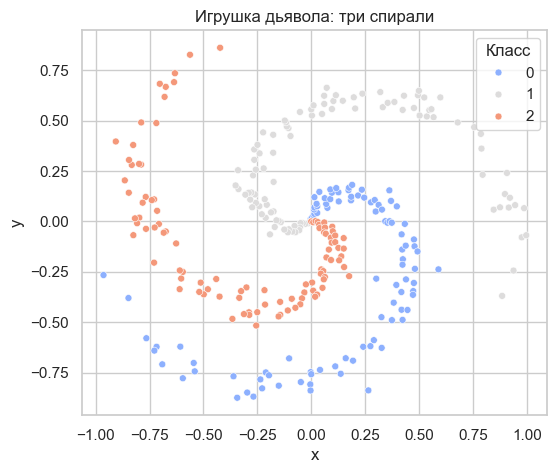

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x=Xs[:, 0], y=Xs[:, 1], hue=ys.astype(str), palette='coolwarm', s=25, ax=ax)
ax.set(title='Игрушка дьявола: три спирали', xlabel='x', ylabel='y')
ax.legend(title='Класс')
save_show(fig, '04_spiral_data.png')

Каждый цвет идёт по своей изогнутой спирали. Прямая не может следовать таким изгибам. Дополнительные эпохи помогают найти более удачные веса, но не дают одному линейному нейрону возможность рисовать спиральную границу.

Сравниваем настройки строго одного нейрона для класса 0 против остальных.

In [25]:
binary_models, binary_rows = {}, []
for config in [apple_configs[0], apple_configs[2], apple_configs[4]]:
    name = config['name']
    model, _ = fit_neuron(s_train_X, ys_binary[s_train], config)
    binary_models[name] = model
    probability = binary_probabilities(model, s_valid_X)
    binary_rows.append({'name': name, 'valid_accuracy': accuracy_score(ys_binary[s_valid], probability >= 0.5),
                        'valid_logloss': log_loss(ys_binary[s_valid], probability)})
binary_table = pd.DataFrame(binary_rows)
display(binary_table)
binary_best = binary_table.sort_values(['valid_accuracy', 'valid_logloss'], ascending=[False, True]).iloc[0]['name']

,name,valid_accuracy,valid_logloss
0,Исходный MSE,0.733333,0.437537
1,NLL + SGD,0.733333,0.426655
2,CE + Adam,0.733333,0.426655


Показываем, как изменилось решение одного нейрона.

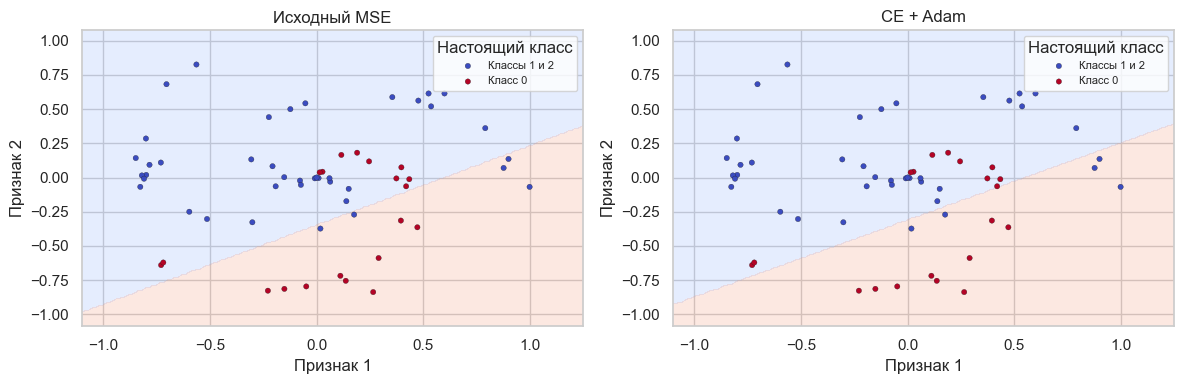

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ['Исходный MSE', binary_best]):
    predict = lambda raw, name=name: predict_network(binary_models[name], s_scaler.transform(raw))
    draw_boundary(ax, predict, Xs[s_valid], ys_binary[s_valid], name, names=['Классы 1 и 2', 'Класс 0'])
fig.tight_layout()
save_show(fig, '05_spiral_one_neuron.png')

Здесь цвета уже бинарные: класс 0 против остальных. Увеличение качества ограничено прямой границей. Из-за двух объединённых классов доля «остальных» равна 2/3, поэтому далее рядом показываем простой ответ большинства и balanced accuracy — среднюю долю правильных ответов отдельно по каждому классу.

### 3.2. Все три класса с одним неизменным линейным слоем
Для исходной трёхклассовой задачи сравниваем SGD при малом шаге и 500 эпохах, SGD с большим шагом и 3000 эпохами, Adam с NLLLoss и Adam с CrossEntropyLoss. Во всех вариантах ровно `Linear(2, 3)` — девять весов и смещений, без скрытых слоёв.

Обучаем один линейный слой разными способами.

In [27]:
multiclass_configs = [
    {'name': 'Исходный SGD', 'optimizer': 'SGD', 'lr': 0.001, 'epochs': 500, 'loss': 'CE'},
    {'name': 'SGD дольше', 'optimizer': 'SGD', 'lr': 0.1, 'epochs': 3000, 'loss': 'CE'},
    {'name': 'Adam + NLL', 'optimizer': 'Adam', 'lr': 0.03, 'epochs': 3000, 'loss': 'NLL'},
    {'name': 'Adam + CE', 'optimizer': 'Adam', 'lr': 0.03, 'epochs': 3000, 'loss': 'CE'}
]
multiclass_models, multiclass_histories, multiclass_rows = {}, {}, []
for config in multiclass_configs:
    torch.manual_seed(SEED)
    model = nn.Sequential(nn.Linear(2, 3))
    optimizer_class = {'SGD': torch.optim.SGD, 'Adam': torch.optim.Adam}[config['optimizer']]
    optimizer = optimizer_class(model.parameters(), lr=config['lr'])
    loss_fn = (lambda scores, labels: nn.NLLLoss()(F.log_softmax(scores, dim=1), labels)) if config['loss'] == 'NLL' else nn.CrossEntropyLoss()
    history = train_network(model, s_train_X, ys[s_train], optimizer, loss_fn, config['epochs'])
    name = config['name']
    multiclass_models[name], multiclass_histories[name] = model, history
    with torch.no_grad():
        probability = model(torch.as_tensor(s_valid_X)).softmax(dim=1).numpy()
    multiclass_rows.append({**config, 'valid_accuracy': accuracy_score(ys[s_valid], probability.argmax(axis=1)),
                            'valid_logloss': log_loss(ys[s_valid], probability)})
multiclass_table = pd.DataFrame(multiclass_rows)
display(multiclass_table)
multiclass_best = multiclass_table.sort_values(['valid_accuracy', 'valid_logloss'], ascending=[False, True]).iloc[0]['name']

,name,optimizer,lr,epochs,loss,valid_accuracy,valid_logloss
0,Исходный SGD,SGD,0.001,500,CE,0.400000,1.003813
1,SGD дольше,SGD,0.100,3000,CE,0.583333,0.701137
2,Adam + NLL,Adam,0.030,3000,NLL,0.583333,0.701137
3,Adam + CE,Adam,0.030,3000,CE,0.583333,0.701137


Сравниваем три класса до и после настройки обучения.

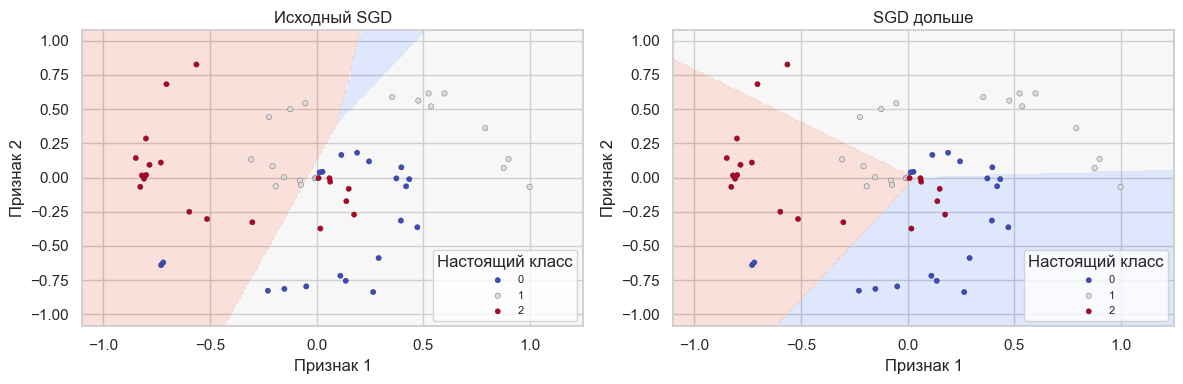

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ['Исходный SGD', multiclass_best]):
    predict = lambda raw, name=name: predict_network(multiclass_models[name], s_scaler.transform(raw))
    draw_boundary(ax, predict, Xs[s_valid], ys[s_valid], name)
fig.tight_layout()
save_show(fig, '06_spiral_three_classes.png')

Фон разделён прямолинейными участками, а настоящие классы изогнуты. Настройка шага и эпох может улучшить исходный результат, но не устраняет это ограничение. Скрытые слои, которые смогут изгибать границы, будут изучаться в следующей работе.

Проверяем выбранные варианты и исходные модели на отложенных спиральных точках.

In [29]:
spiral_test_rows, saved_predictions = [], pd.DataFrame({'row': s_test, 'actual_three': ys[s_test], 'actual_binary': ys_binary[s_test]})
for task, models, names, labels in [
    ('Один нейрон, два класса', binary_models, ['Исходный MSE', binary_best], ys_binary),
    ('Линейный слой, три класса', multiclass_models, ['Исходный SGD', multiclass_best], ys)]:
    for name in dict.fromkeys(names):
        predicted = predict_network(models[name], s_test_X)
        column = task + ': ' + name
        saved_predictions[column] = predicted
        spiral_test_rows.append({'task': task, 'name': name,
            'test_accuracy': accuracy_score(labels[s_test], predicted),
            'test_balanced_accuracy': balanced_accuracy_score(labels[s_test], predicted)})
spiral_test_table = pd.DataFrame(spiral_test_rows)
display(spiral_test_table)
print('Бинарный ответ «остальные» всегда:', accuracy_score(ys_binary[s_test], np.zeros(len(s_test), dtype=int)))
print('Случайный равномерный ответ для трёх классов: ожидаемая accuracy = 1/3')

,task,name,test_accuracy,test_balanced_accuracy
0,"Один нейрон, два класса",Исходный MSE,0.733333,0.662500
1,"Один нейрон, два класса",CE + Adam,0.716667,0.662500
2,"Линейный слой, три класса",Исходный SGD,0.250000,0.250000
3,"Линейный слой, три класса",SGD дольше,0.483333,0.483333


Бинарный ответ «остальные» всегда: 0.6666666666666666
Случайный равномерный ответ для трёх классов: ожидаемая accuracy = 1/3


Сохраняем результаты и формируем простой вывод.

In [30]:
apple_table.to_csv(REPORT / 'apples_validation.csv', index=False)
apple_test_table.to_csv(REPORT / 'apples_test.csv', index=False)
binary_table.to_csv(REPORT / 'spiral_binary_validation.csv', index=False)
multiclass_table.to_csv(REPORT / 'spiral_three_validation.csv', index=False)
spiral_test_table.to_csv(REPORT / 'spiral_test.csv', index=False)
saved_predictions.to_csv(REPORT / 'spiral_predictions.csv', index=False)
a_probability = binary_probabilities(apple_models[apple_best], a_test_X)
pd.DataFrame({'row': a_test, 'actual': ya[a_test], 'probability': a_probability,
              'prediction': a_probability >= 0.5}).to_csv(REPORT / 'apples_predictions.csv', index=False)
a_accuracy = accuracy_score(ya[a_test], a_probability >= 0.5)
analysis = (f'Изучил возможности PyTorch: создал нейрон, выполнил прямой проход, вычисление потерь '
            f'и обновление весов. Для «Яблок и груш» выбран {apple_best}; на {len(a_test)} итоговых строках '
            f'accuracy = {a_accuracy:.1%}. На спирали сравнил настройки без скрытых слоёв. '
            'Бинарная версия и исходные три класса проверены отдельно. Прямые границы ограничивают качество: '
            'большее число эпох не превращает один линейный слой в многослойную сеть.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'apples_selected': apple_best, 'apples_accuracy': a_accuracy,
           'apples_test': apple_test_table.to_dict('records'), 'spiral_binary_selected': binary_best,
           'spiral_three_selected': multiclass_best, 'spiral_test': spiral_test_table.to_dict('records'),
           'spiral_seed': SEED, 'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
sources = {'apple_url': apple_url, 'spiral': 'Формула методички, с. 137; 100 точек на класс, шум 0.2, seed 17',
           'sha256': {str(apple_path.relative_to(ROOT)): hashlib.sha256(apple_path.read_bytes()).hexdigest()}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Изучил возможности PyTorch: создал нейрон, выполнил прямой проход, вычисление потерь и обновление весов. Для «Яблок и груш» выбран CE + Adam; на 200 итоговых строках accuracy = 98.0%. На спирали сравнил настройки без скрытых слоёв. Бинарная версия и исходные три класса проверены отдельно. Прямые границы ограничивают качество: большее число эпох не превращает один линейный слой в многослойную сеть.

378

## 4. Заключение
Изучил возможности библиотеки PyTorch. Разработал один нейрон, освоил тензоры, прямой проход, расчёт градиентов и изменение весов. Сравнил MSE, NLLLoss и CrossEntropyLoss, изменял шаг, число эпох и оптимизатор.

Проверил простую модель на «Яблоках и грушах» и сложных спиралях. Увидел, что настройка обучения помогает, но прямой границы недостаточно для полного разделения спиралей. Различие одного бинарного нейрона и трёхклассового выходного слоя указано явно; скрытые слои в этой работе не добавлялись.

На итоговой проверке «Яблок и груш» выбранный нейрон дал 98% правильных ответов против 97,5% исходного. На трёхклассовой спирали настройка обучения повысила accuracy с 25% до 48,3%. В бинарном опыте результат выбранного по части подбора варианта оказался ниже: 71,7% против 73,3%; средняя точность по двум классам у обоих одинакова — 66,25%. Это показывает ограничение прямой границы и то, что выигрыш на части подбора не гарантирует выигрыш на новых точках.

## 5. Ответы на контрольные вопросы
**1. Что влияет на качество со стороны модели?**  
Архитектура, активации, начальные веса, оптимизатор, шаг обучения, число эпох, размер порции данных и регуляризация. Их задаёт разработчик, хотя подходящие значения зависят и от задачи.

**2. Что влияет со стороны данных?**  
Количество и разнообразие примеров, ошибки и пропуски, качество разметки, масштаб признаков и соотношение классов. Проверочная часть должна соответствовать будущему применению модели.

**3. Как задают сеть в PyTorch?**  
Через `nn.Sequential` — последовательность слоёв; или через собственный класс `nn.Module` с методом `forward`. Во втором случае внутри `forward` можно использовать слои и функции `torch.nn.functional`.

**4. Как загрузить CSV?**  
Правильный вариант **а)**: `dataset = read_csv("data.csv")`, если функция импортирована из pandas. Обычно пишут `import pandas as pd`, затем `dataset = pd.read_csv("data.csv")`.

## 6. Источники
- Методичка *Practicum_AI_Methods.pdf*, с. 124–131; формула спиралей — с. 137.
- [Учебный файл DLSchool «Яблоки и груши»](https://github.com/DLSchool/dlschool_old/blob/6a0084864d3dd72e19b9bc818fcf4fced6d275cd/materials/homeworks/hw04/data/apples_pears.csv).
- [PyTorch: CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html).
- [PyTorch: NLLLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.NLLLoss.html).